## 15.1. Spot detection

### 1. one fov: X10_Y2

- In this step, we use anchor file (the 6th channel): 490LS

In [1]:
# Import library

import glob
import numpy as np
import pandas as pd
import skimage as ski
from skimage import io, filters
import matplotlib.pyplot as plt
from skimage.filters import gaussian
from skimage.morphology import white_tophat, disk

In [2]:
import trackpy as tp

In [3]:
path = '/Users/chann/Downloads/F1 Systems bio/Project/code/realistic_data/selected-tiles'

In [4]:
codebook_df = pd.read_csv("/Users/chann/Downloads/F1 Systems bio/Project/code/realistic_data/taglist.csv")
print(codebook_df.head())

     Name  Code
0  Adra1b  AACG
1  Atp1a2  TGGT
2  Atp2b4  TTGC
3  Bcl11b  TGCG
4    Car2  GTTG


In [5]:
# Spot detection - preprocessing - use this

fov = "X10_Y2"

# only take file anchor (Atto_490LS)
anchor_files = sorted(glob.glob(f'{path}/out_opt_flow_registered_{fov}_c*_Atto_490LS.tif'))
print(f"Number of anchor file: {len(anchor_files)}")

Number of anchor file: 4


In [6]:

# Stack all of 4 anchor images into 1
anchor_list = []
for f in anchor_files:
    img = ski.io.imread(f)
    anchor_list.append(img)
print(anchor_list)
anchor_stack = np.stack(anchor_list, axis=0)
anchor_combined = np.max(anchor_stack, axis=0)

[array([[366, 295, 241, ..., 118, 117, 120],
       [394, 291, 226, ..., 117, 121, 124],
       [366, 265, 203, ..., 121, 128, 128],
       ...,
       [129, 128, 127, ..., 130, 130, 130],
       [130, 130, 123, ..., 135, 139, 134],
       [128, 126, 122, ..., 138, 135, 131]],
      shape=(1000, 1000), dtype=uint16), array([[231, 208, 196, ..., 148, 139, 133],
       [228, 202, 199, ..., 147, 139, 133],
       [218, 199, 211, ..., 146, 141, 137],
       ...,
       [146, 143, 140, ..., 150, 153, 153],
       [141, 138, 144, ..., 152, 154, 152],
       [144, 139, 138, ..., 152, 148, 144]],
      shape=(1000, 1000), dtype=uint16), array([[294, 240, 214, ..., 116, 111, 113],
       [275, 237, 216, ..., 120, 114, 116],
       [246, 222, 220, ..., 129, 120, 116],
       ...,
       [138, 138, 144, ..., 125, 129, 132],
       [139, 140, 145, ..., 126, 125, 132],
       [148, 145, 144, ..., 127, 127, 140]],
      shape=(1000, 1000), dtype=uint16), array([[344, 269, 227, ..., 146, 137, 136],
 

In [7]:

#Pre-processing image

def pre_im(im):
    im = im.astype(float)
    im_substraction = white_tophat(im, disk(3))
    im_gauss = gaussian(im_substraction, sigma=0.8)
    return im_gauss

anchor_processed = pre_im(anchor_combined)

#Detect spot

spots_df = tp.locate(
    anchor_processed,
    diameter=5,
    percentile=0,  #
    separation=2  #
)
spots_df_filtered = spots_df[spots_df['mass'] > 50]

print(f"Number of {len(spots_df)} spots detected")
print(spots_df_filtered.head())


Number of 1420 spots detected
          y           x        mass      size       ecc     signal  \
0  2.797753   36.179775  349.673968  1.311145  0.163178  53.040433   
1  3.593750  996.375000   62.862736  1.237437  0.074074   9.822302   
2  5.204225    3.922535  278.953390  1.216089  0.101379  43.218131   
3  5.017442   37.011628  337.887205  1.305178  0.190774  45.182591   
4  8.969697   31.117845  583.444767  1.271283  0.033375  80.542880   

      raw_mass        ep  
0  2788.004373  0.003855  
1   481.242547  0.023930  
2  1788.677434  0.006055  
3  2594.244314  0.004147  
4  3716.673590  0.002881  


In [8]:
#Save spot coordination

df_spots_preprocessed = pd.DataFrame({
    'Spot_id': range(len(spots_df)),
    'y': spots_df.iloc[:, 0],
    'x': spots_df.iloc[:, 1]
})

df_spots_preprocessed.to_csv(
    '/Users/chann/Downloads/F1 Systems bio/Project/code/Results/Intermediates/Rough/Spot detection/spots_detected_preprocessed.csv',
    index=False)
print(df_spots_preprocessed.head())


   Spot_id         y           x
0        0  2.797753   36.179775
1        1  3.593750  996.375000
2        2  5.204225    3.922535
3        3  5.017442   37.011628
4        4  8.969697   31.117845


#### Summerize


In [9]:
fov = "X10_Y2"

# only take file anchor (Atto_490LS)
anchor_files = sorted(glob.glob(f'{path}/out_opt_flow_registered_{fov}_c*_Atto_490LS.tif'))

# Stack all of 4 anchor images into 1
anchor_list = []
for f in anchor_files:
    img = ski.io.imread(f)
    anchor_list.append(img)
anchor_stack = np.stack(anchor_list, axis=0)
anchor_combined = np.max(anchor_stack, axis=0)

#Pre-processing image
def pre_im(im):
    im = im.astype(float)
    im_substraction = white_tophat(im, disk(3))
    im_gauss = gaussian(im_substraction, sigma=0.8)
    return im_gauss
anchor_processed = pre_im(anchor_combined)

#Detect spot
spots_df = tp.locate(
    anchor_processed,
    diameter=5,
    percentile=0,  #
    separation=2  #
)
spots_df_filtered = spots_df[spots_df['mass'] > 50]

#Save spot coordinate
df_spots_preprocessed = pd.DataFrame({
    'Spot_id': range(len(spots_df)),
    'y': spots_df.iloc[:, 0],
    'x': spots_df.iloc[:, 1]
})

df_spots_preprocessed.to_csv(
    '/Users/chann/Downloads/F1 Systems bio/Project/code/Results/Intermediates/Rough/Spot detection/spots_detected_preprocessed.csv',
    index=False)
print(df_spots_preprocessed.head())

   Spot_id         y           x
0        0  2.797753   36.179775
1        1  3.593750  996.375000
2        2  5.204225    3.922535
3        3  5.017442   37.011628
4        4  8.969697   31.117845


## 15.2. Barcode decoding

### 1. Stack image

In [10]:
## Stack image
#1_Preparation:

fov = "X10_Y2"
#Read image

def read_image(round, channel):
    file_path = f"{path}/out_opt_flow_registered_{fov}_{round}_{channel}.tif"
    return io.imread(file_path)


#List of channel and round
channel_name = ['Atto_425', 'Alexa_488', 'Alexa_568', 'Alexa_647']
number_channel = len(channel_name)

round_name = ['c01', 'c02', 'c03', 'c04']
number_round = len(round_name)

# Create the empty matrix
height, width = 1000, 1000
stack_image = np.zeros((number_round, number_channel, height, width))

# Put all the image in one fov in 4D matrix
for r, r_name in enumerate(round_name):
    for c, c_name in enumerate(channel_name):
        stack_image[r, c] = read_image(round=r_name, channel=c_name)

print(stack_image.shape)
print(stack_image.dtype)
#image

(4, 4, 1000, 1000)
float64


### 2. Decoding (percentile clipping)

#### 2.1. Percentile clipping

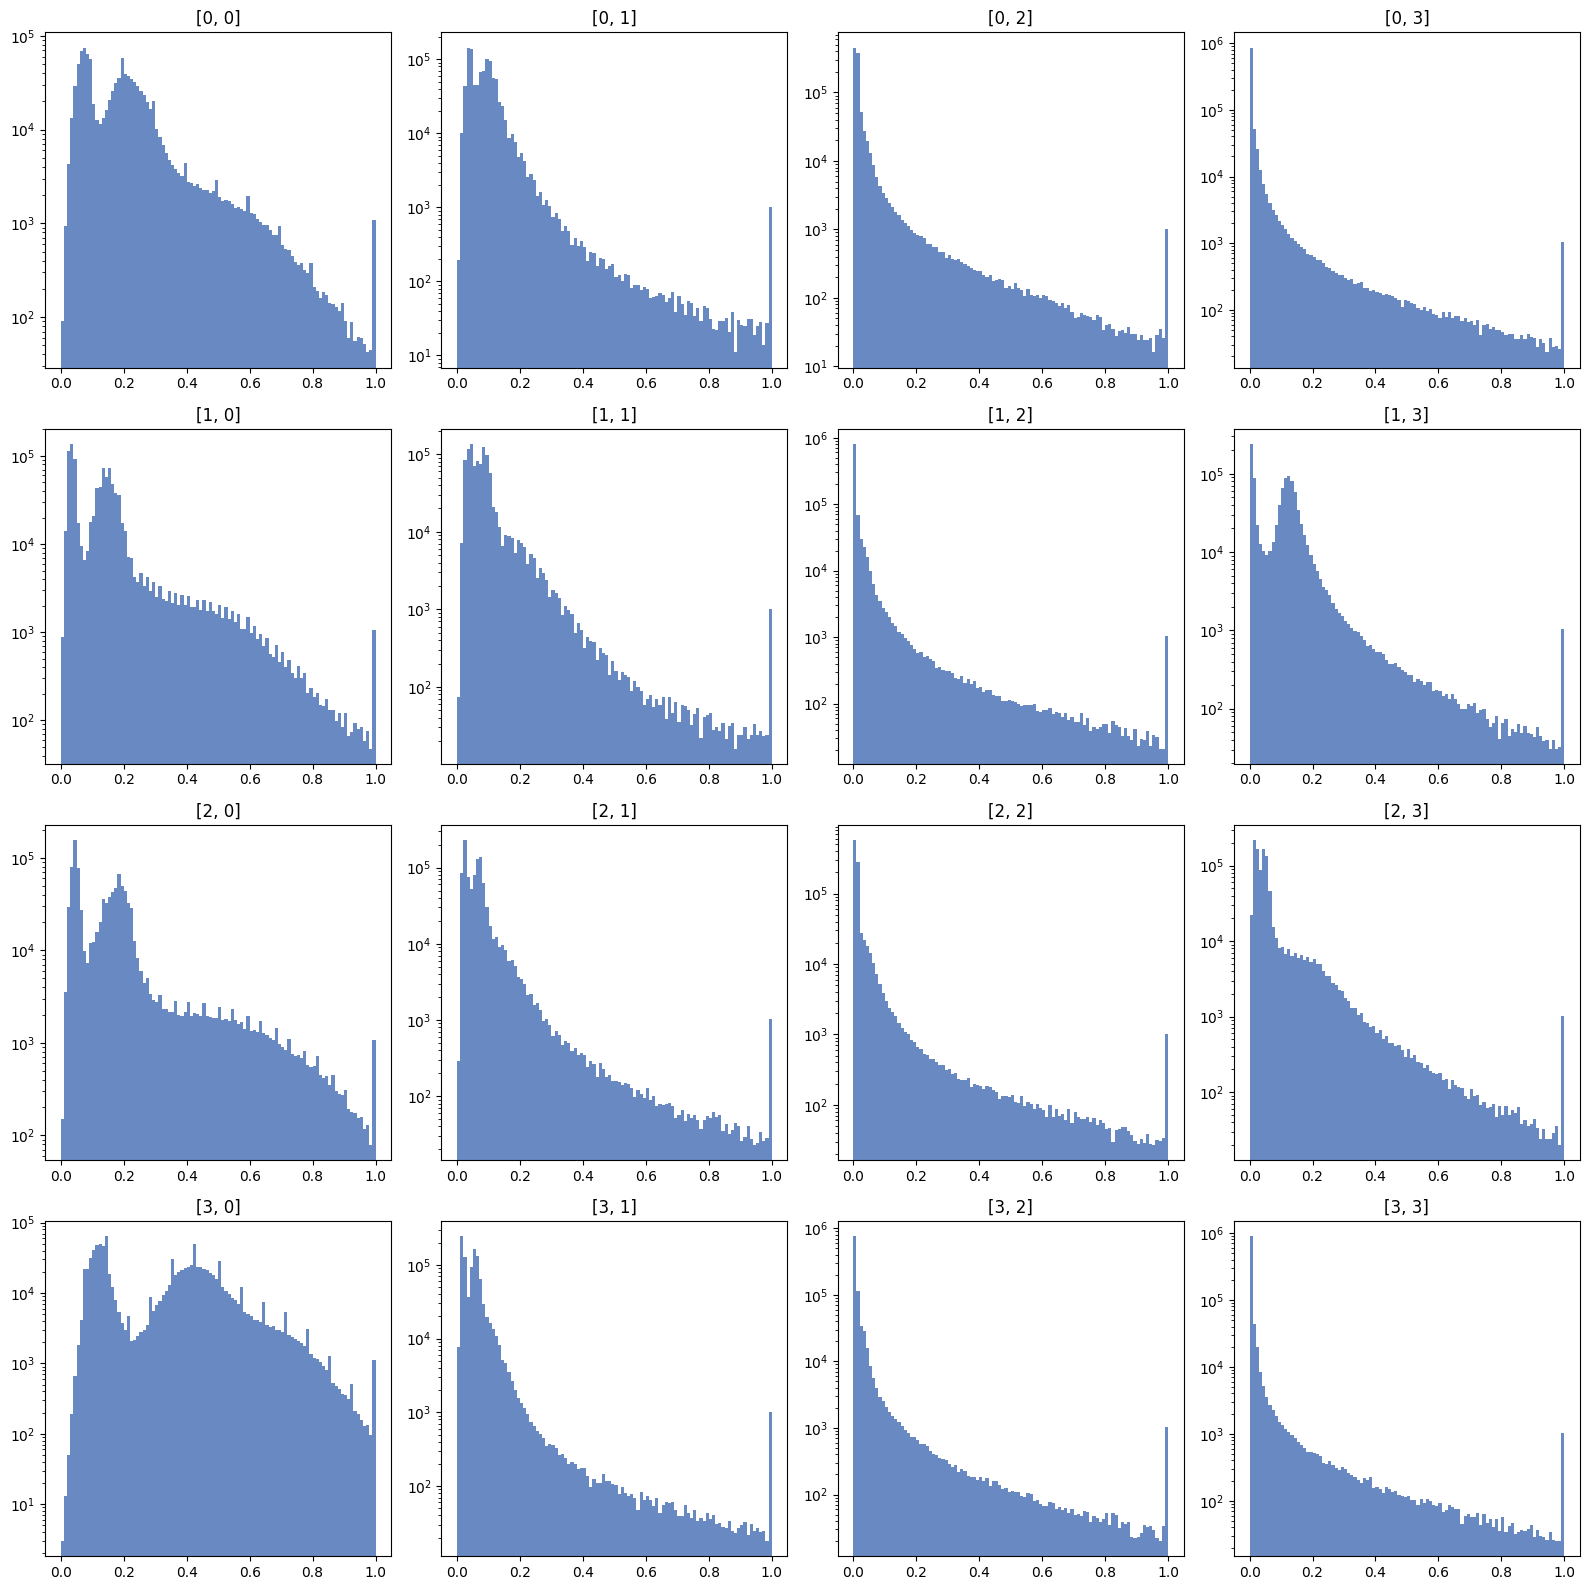

In [11]:
# 1 image: Percentile clipping + normalization - 99.9%

def percentile_clip(channel, lower_percentile, upper_percentile):
    lower = np.percentile(channel, lower_percentile)
    upper = np.percentile(channel, upper_percentile)

    clipped = np.clip(channel, None, upper)
    normalized = (clipped - lower) / (upper - lower)
    normalized = np.clip(normalized, 0, 1)

    return lower, upper, normalized


# 16 images
def all_percentile(stack_image, lower_percentile, upper_percentile):
    stack_normalized = np.zeros_like(stack_image)
    for i in range(4):
        for j in range(4):
            channel = stack_image[i, j]
            lower, upper, normalized = percentile_clip(channel, lower_percentile, upper_percentile)
            stack_normalized[i, j] = normalized
    return stack_normalized


stack_image_normalized = all_percentile(stack_image, lower_percentile=0, upper_percentile=99.9)


#Plotting
def plot_stack_normalized(stack_normalized):
    fig, axes = plt.subplots(4, 4, figsize=(16, 16))
    for i in range(4):
        for j in range(4):
            axes[i, j].hist(stack_normalized[i, j].flatten(), bins=100, color = "#6889C2", log=True)
            axes[i, j].set_title(f'{[i, j]}')

    plt.tight_layout()
    plt.savefig("/Users/chann/Downloads/F1 Systems bio/Project/code/src/iss_decoding/Barcode decoding/percentile_clipping.png")
    plt.show()


plot_stack_normalized(stack_image_normalized)




#### 2.2. Decoding

In [12]:
#decoding - problem - A bias - 99.9%

base_letters = ['A', 'C', 'G', 'T']
spots_array = df_spots_preprocessed[['y', 'x']].to_numpy()

decoded_sequences = []
for y, x in spots_array:
    y, x = int(round(y)), int(round(x))
    sequencing = ""
    for i in range(4):
        values = stack_image_normalized[i, :, y, x]
        index_max = np.argmax(values)
        sequencing += base_letters[index_max]
    decoded_sequences.append(sequencing)

print(decoded_sequences[:20])

['AATT', 'ATTA', 'AAAA', 'AAAC', 'AAAA', 'AAAA', 'AAAA', 'AAAA', 'AAAA', 'TACG', 'AAAA', 'AAAA', 'AAAT', 'AATA', 'TGGT', 'CTCC', 'GGTC', 'AAAA', 'AAAA', 'AAAA']


Normally, we can use percentile clipping +  normalization to normalize the data but in this dataset, we met a problem: the difference baseline in rounds. -> need to do histogram matching per channel in round.

#### 2.3. Mapping to codebook

In [ ]:
%%sql


In [13]:
# Create dict: sequence -> gene name
seq_to_gene = dict(zip(codebook_df['Code'], codebook_df['Name']))

# Map decoded_after to gene name
decoded_genes = [seq_to_gene.get(seq, "invalid") for seq in decoded_sequences]

print(decoded_genes[:20])

['invalid', 'Tgtp1', 'invalid', 'Rprml', 'invalid', 'invalid', 'invalid', 'invalid', 'invalid', 'Gapdh', 'invalid', 'invalid', 'Foxp2', 'invalid', 'Atp1a2', 'invalid', 'invalid', 'invalid', 'invalid', 'invalid']


#### 2.4. Calculate the efficiency

In [14]:
gene_series = pd.Series(decoded_genes) #Create series
invalid_spot = (gene_series == "invalid") #Compare
n_invalid = invalid_spot.sum()
print(f"unmatched: {n_invalid} / {len(decoded_genes)} ({n_invalid / len(decoded_genes) * 100:.1f}%)")

unmatched: 1019 / 1420 (71.8%)


Above result show the percent of ummatch decoded spot -> 71.8% => need to fix by histogram matching

### 3. Decoding (histogram matching by starfish)

#### 3.1. Histogram matching

#### Preprocessing

In [15]:
# Distribution normalization by Starfish
## Distribution normalization 4 channels in 1 round

## Import library
import starfish
import numpy as np
from starfish import ImageStack
from starfish.image import Filter
from starfish.types import Axes

In [16]:
## Step 1: Slice => take round 1

round1_channels = stack_image_normalized[0:1].astype(np.float32)
print(round1_channels.shape)
print(round1_channels.dtype)  # float32
print(round1_channels.min(), round1_channels.max())  # -> (1, 4, 1000, 1000)

## Step 2: add z
round1_5d = round1_channels[:, :, np.newaxis, :, :]
print(round1_5d.shape)  # (1,4,1000,1000) -> (1,4,1,1000,1000)

## Step 3: Create initial ImageStack
stack_round1 = ImageStack.from_numpy(round1_5d)
print(stack_round1)  # <starfish.ImageStack (r: 1, c: 4, z: 1, y: 1000, x: 1000)>

(1, 4, 1000, 1000)
float32
0.0 1.0
(1, 4, 1, 1000, 1000)
<starfish.ImageStack (r: 1, c: 4, z: 1, y: 1000, x: 1000)>


#### Match histogram

In [17]:
## Step 4: Match histogram
mh_channel = starfish.image.Filter.MatchHistograms({Axes.CH})
scaled_channel = mh_channel.run(stack_round1, in_place=False, verbose=True)  # verbose = false: not print progress bar
print(scaled_channel)

Calculating reference distribution...


100%|██████████| 4/4 [00:00<00:00, 1874.34it/s]

<starfish.ImageStack (r: 1, c: 4, z: 1, y: 1000, x: 1000)>


#### Plotting

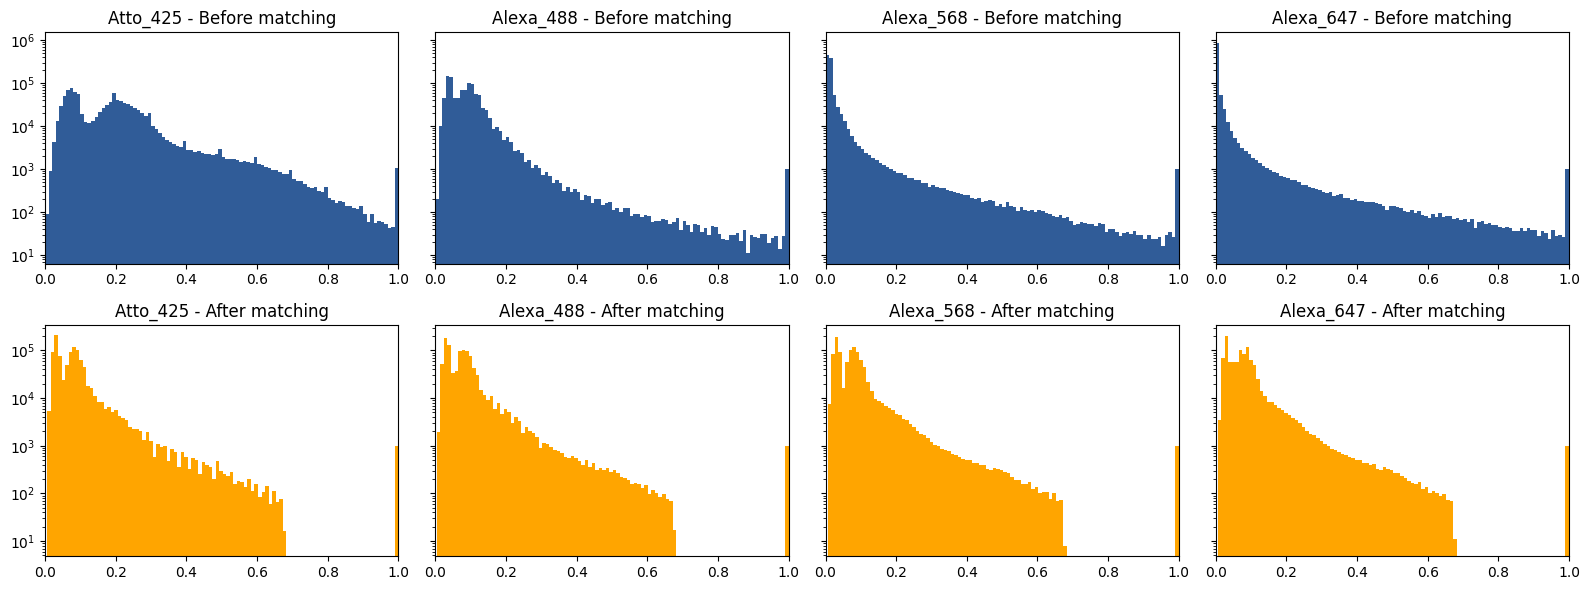

In [18]:
## Plotting
channel_name = ['Atto_425', 'Alexa_488', 'Alexa_568', 'Alexa_647']

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey='row')

for c in range(4):
    before = stack_round1.xarray.values[0, c, 0].flatten()
    after = scaled_channel.xarray.values[0, c, 0].flatten()

    # Before match histogram
    axes[0, c].hist(before, bins=100, color='#305C98',log=True)
    axes[0, c].set_title(f"{channel_name[c]} - Before matching")
    axes[0, c].set_xlim(0, 1)

    # After match histogram
    axes[1, c].hist(after, bins=100, color='orange',log = True)
    axes[1, c].set_title(f"{channel_name[c]} - After matching")
    axes[1, c].set_xlim(0, 1)

plt.tight_layout()
plt.show()

#### 3.2. Histogram matching (Function)

#### One round

In [19]:
## Function 1 round
def match_histogram (image_stacked,x,y):

    round_ch = image_stacked[x:y].astype(np.float32)
    round_ch_5d = round_ch[:,:,np.newaxis,:,:]

    round_stack = ImageStack.from_numpy(round_ch_5d)
    mh_round_ch = starfish.image.Filter.MatchHistograms({Axes.CH})
    scaled_round_ch = mh_round_ch.run(round_stack, in_place=False, verbose = False)
    return round_ch_5d, scaled_round_ch #return both original 5d image + scaled image.

#### Four round

In [20]:
## 4 rounds
results_4round = []
for r in range(4):
    round_5d_original, scaled_stack = match_histogram(stack_image_normalized, r, r + 1)
    results_4round.append(scaled_stack)

100%|██████████| 4/4 [00:00<00:00, 214.58it/s]


#### Plotting

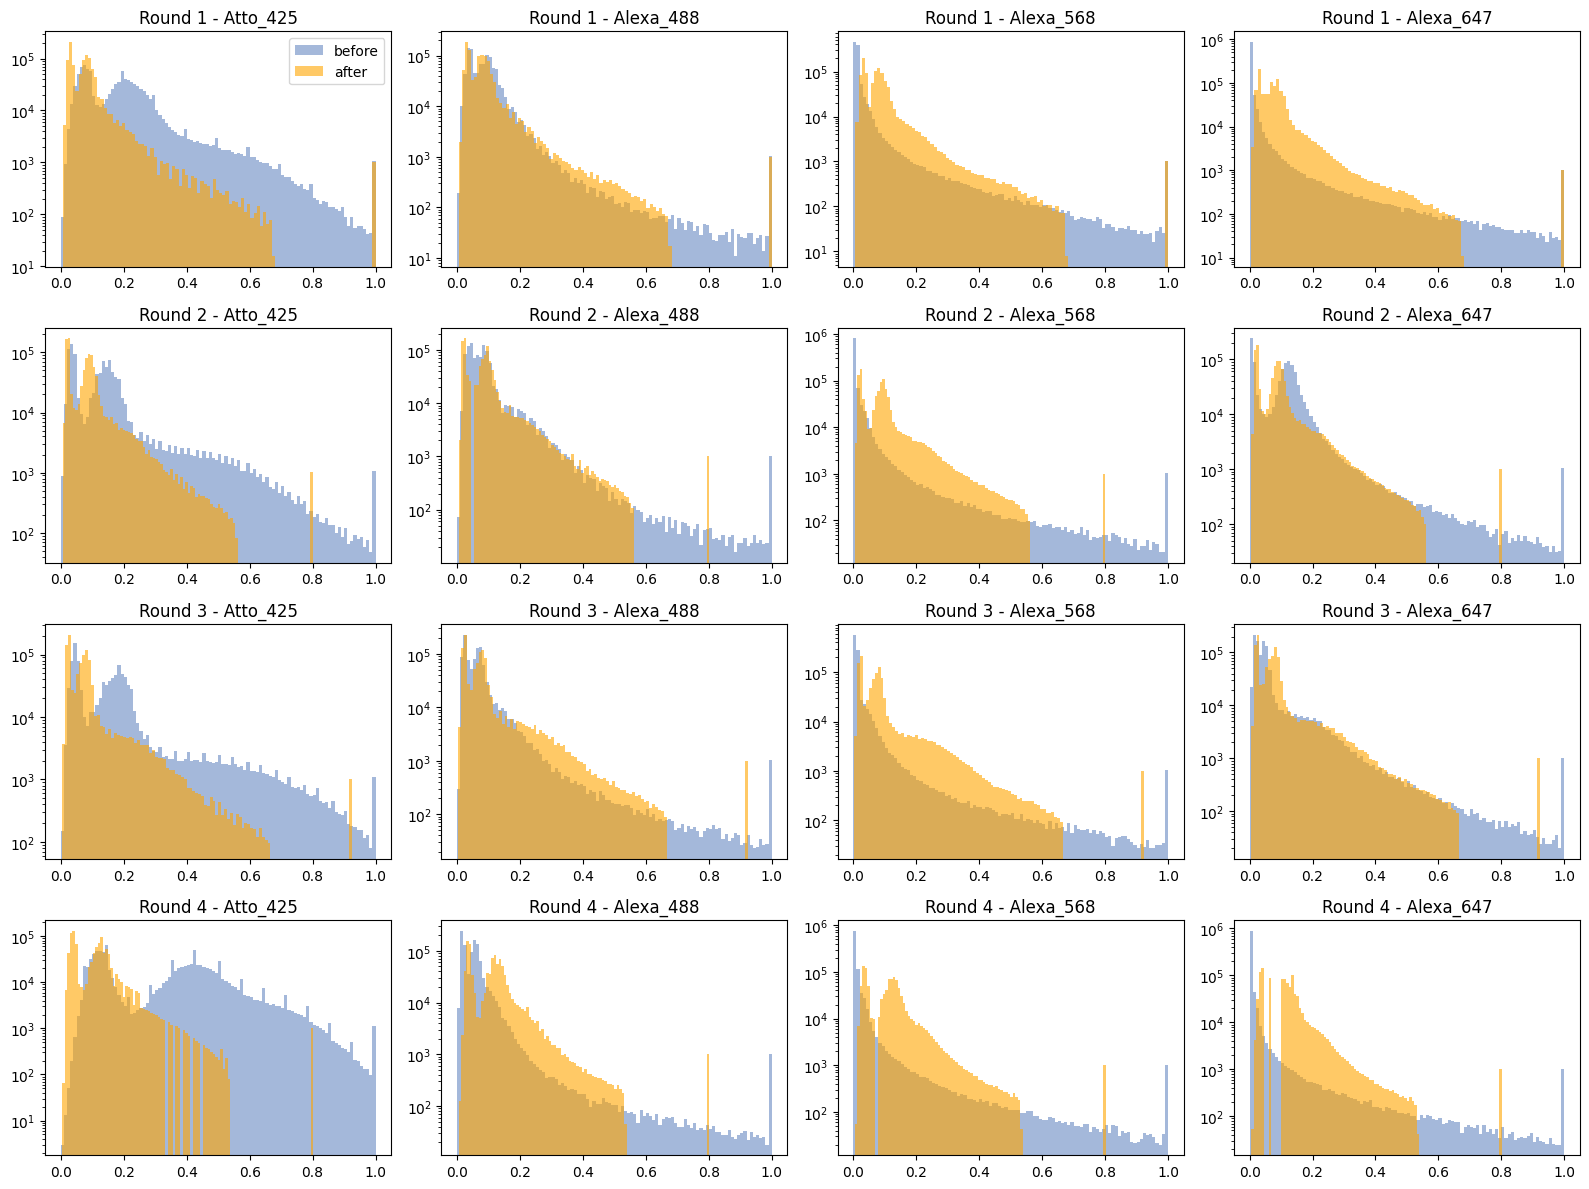

In [21]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for r in range(4):
    for c in range(4):
        before_match = stack_image_normalized[r, c].flatten()
        after_match = results_4round[r].xarray.values[0, c, 0].flatten()  #from imagestack(5D) -> numpy array

        axes[r, c].hist(before_match, bins=100, color='#6889C2', alpha=0.6, label='before')
        axes[r, c].hist(after_match, bins=100, color='orange', alpha=0.6, label='after')
        axes[r, c].set_title(f"Round {r + 1} - {channel_name[c]}")
        axes[r, c].set_yscale('log')

axes[0, 0].legend()
plt.tight_layout()
plt.savefig("/Users/chann/Downloads/F1 Systems bio/Project/code/src/iss_decoding/Barcode decoding/histogram_matching")
plt.show()

#### 3.3. Decoding

#### Change the datatype

In [22]:
## Change the datatype after normalizing # Claude

list_of_rounds = []
for r in range(4):
    array_5d = results_4round[r].xarray.values     # (1, 4, 1, Y, X)
    array_3d = array_5d[0, :, 0, :, :]             # (4, Y, X) = (channel, y, x)
    list_of_rounds.append(array_3d)

matched_np = np.stack(list_of_rounds, axis=0)      # (4, 4, Y, X) = (round, channel, y, x) => use this for decoding
print(matched_np.shape)

(4, 4, 1000, 1000)


#### Decoding


In [23]:
## Decode

base_letters = ['A', 'C', 'G', 'T']
spots_coordinates = df_spots_preprocessed[['y', 'x']].to_numpy()  # list of spot coordinates


def decode(data, spots_array):
    n_round = data.shape[0]
    decoded_sequences = []

    for y, x in spots_array:
        y, x = int(round(y)), int(round(x))
        sequence = ""
        for r in range(n_round):
            values = data[r, :, y, x]
            index_max = np.argmax(values)
            base = base_letters[index_max]
            sequence += base
        decoded_sequences.append(sequence)

    return decoded_sequences


decoded_after = decode(matched_np, spots_coordinates)
print(decoded_after[:20])

['TGTT', 'GGTT', 'ACCG', 'TTTC', 'TGCC', 'AAAA', 'TGGT', 'TGGC', 'TGTT', 'TGCG', 'TGCG', 'TGGT', 'TGTT', 'TGGT', 'TGGT', 'CTCC', 'GGGC', 'TTTA', 'GTTA', 'TGGT']


#### Mapping to codebook

In [24]:
# Create dict: sequence -> gene name
seq_to_gene = dict(zip(codebook_df['Code'], codebook_df['Name']))

# Map decoded_after to gene name
decoded_genes = [seq_to_gene.get(seq, "invalid") for seq in decoded_after]

print(decoded_genes[:20])

['invalid', 'invalid', 'Car4', 'invalid', 'invalid', 'invalid', 'Atp1a2', 'invalid', 'invalid', 'Bcl11b', 'Bcl11b', 'Atp1a2', 'invalid', 'Atp1a2', 'Atp1a2', 'invalid', 'Itm2a', 'invalid', 'invalid', 'Atp1a2']


In [25]:
result_df = pd.DataFrame({
    "spot_id": range(len(decoded_after)),
    "y": df_spots_preprocessed["y"].to_numpy(),
    "x": df_spots_preprocessed["x"].to_numpy(),
    "barcode": decoded_after,
    "gene": decoded_genes,
})

result_df["valid"] = result_df["gene"] != "invalid"

print(result_df.head(20))

    spot_id          y           x barcode     gene  valid
0         0   2.797753   36.179775    TGTT  invalid  False
1         1   3.593750  996.375000    GGTT  invalid  False
2         2   5.204225    3.922535    ACCG     Car4   True
3         3   5.017442   37.011628    TTTC  invalid  False
4         4   8.969697   31.117845    TGCC  invalid  False
5         5  11.214286    4.857143    AAAA  invalid  False
6         6  12.390244   42.146341    TGGT   Atp1a2   True
7         7  12.300000   36.400000    TGGC  invalid  False
8         8  15.051282   47.384615    TGTT  invalid  False
9         9  17.146341  458.975610    TGCG   Bcl11b   True
10       10  17.833333  454.166667    TGCG   Bcl11b   True
11       11  18.850000   39.022727    TGGT   Atp1a2   True
12       12  18.829787  985.957447    TGTT  invalid  False
13       13  20.500000  991.000000    TGGT   Atp1a2   True
14       14  22.136210   27.160745    TGGT   Atp1a2   True
15       15  22.000000   49.817043    CTCC  invalid  Fal

#### Calculate the efficiency

In [26]:
counts = pd.Series(decoded_genes).value_counts()
print(counts.head(20))

n_invalid = (pd.Series(decoded_genes) == "invalid").sum()
print(f"unmatched: {n_invalid} / {len(decoded_genes)} ({n_invalid/len(decoded_genes)*100:.1f}%)")

invalid    636
Atp1a2     195
Bcl11b     110
Gapdh       76
Cux2        64
Coch        46
Zdhhc12     33
Flt1        25
Col12a1     22
Spon1       17
Foxp2       15
Rorb        13
Reln        12
Atp2b4      12
Luzp2       11
Cryab       11
Inpp4b      11
Tgtp1       11
Itm2a       11
Nek7        10
Name: count, dtype: int64
unmatched: 636 / 1420 (44.8%)
